<a href="https://colab.research.google.com/github/tanu100/DeepLearning/blob/main/KerasFunctionalModel/KerasFunctionalModel_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd

In [2]:
data=pd.read_csv("https://raw.githubusercontent.com/MakroMB/student-performance-analysis/main/data/student-mat.csv",sep=';')

In [3]:
data

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20,U,LE3,A,2,2,services,services,...,5,5,4,4,5,4,11,9,9,9
391,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,3,14,16,16
392,MS,M,21,R,GT3,T,1,1,other,other,...,5,5,3,3,3,3,3,10,8,7
393,MS,M,18,R,LE3,T,3,2,services,other,...,4,4,1,3,4,5,0,11,12,10


In [4]:
print(data.shape)

(395, 33)


In [11]:
data.isna().sum()


,0
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


In [14]:
print(data['G3'].head())

0     6
1     6
2    10
3    15
4    10
Name: G3, dtype: int64


In [13]:
data['G3'].value_counts()

,count
G3,
10,56
11,47
0,38
15,33
8,32
12,31
13,31
9,28
14,27


In [6]:
df1=data[['G1','G2']]
df2=data[['age','health']]
df3=data[['studytime', 'failures', 'absences']]
y=data['G3']

In [8]:
from sklearn.model_selection import train_test_split

(
    X_academic_train, X_academic_test,
    X_personal_train, X_personal_test,
    X_study_train, X_study_test,
    y_train, y_test
) = train_test_split(
    df1,
    df2,
    df3,
    y,
    test_size=0.2,
    random_state=42
)

In [16]:
from keras.models import Model
from keras.layers import *

model= Model()

academic_input=Input(shape=(2,))
personal_input=Input(shape=(2,))
study_input=Input(shape=(3,))


academic_layer_1=Dense(32,activation='relu')(academic_input)
personal_layer_1=Dense(32,activation='relu')(personal_input)
study_layer_1=Dense(32,activation='relu')(study_input)

# Instantiate Concatenate layer and call it on the input list
merged=Concatenate()([academic_layer_1,personal_layer_1,study_layer_1])

process_layer=Dense(64,activation='relu')(merged)

final_layer=Dense(1,activation='linear')(process_layer)

model=Model(
    inputs=[academic_input,personal_input,study_input],
    outputs=final_layer
)


In [19]:
from keras.src.optimizers import optimizer
model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

In [20]:
model.fit(
    [X_academic_train,X_personal_train,X_study_train],
    y_train,
    epochs=10,
    batch_size=50,
    validation_split=0.2
)

Epoch 1/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 87ms/step - loss: 57.5900 - mae: 6.9529 - val_loss: 30.6606 - val_mae: 4.9662
Epoch 2/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 19.7813 - mae: 3.8419 - val_loss: 18.6994 - val_mae: 3.1202
Epoch 3/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 12.7462 - mae: 2.7111 - val_loss: 15.2636 - val_mae: 2.6775
Epoch 4/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 11.8262 - mae: 2.4186 - val_loss: 12.6606 - val_mae: 2.4175
Epoch 5/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 9.7531 - mae: 2.1712 - val_loss: 9.6669 - val_mae: 2.1331
Epoch 6/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 7.7137 - mae: 1.9409 - val_loss: 8.1399 - val_mae: 1.9742
Epoch 7/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 6.8684 - mae: 1.8733 - val_loss: 7.1830 - val_mae: 1.8622
Epoch 8/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 6.1085 - mae: 1.7234 - val_loss: 6.1780 - val_mae: 1.6208
Epoch 9/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 5.4741 - mae: 1

In [21]:
test_loss,test_mae=model.evaluate(
    [X_academic_test,X_personal_test,X_study_test],
    y_test
)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 5.5155 - mae: 1.7121


In [22]:
print("Test Loss:", test_loss)
print("Test MAE:", test_mae)

Test Loss: 5.515514373779297
Test MAE: 1.7120784521102905


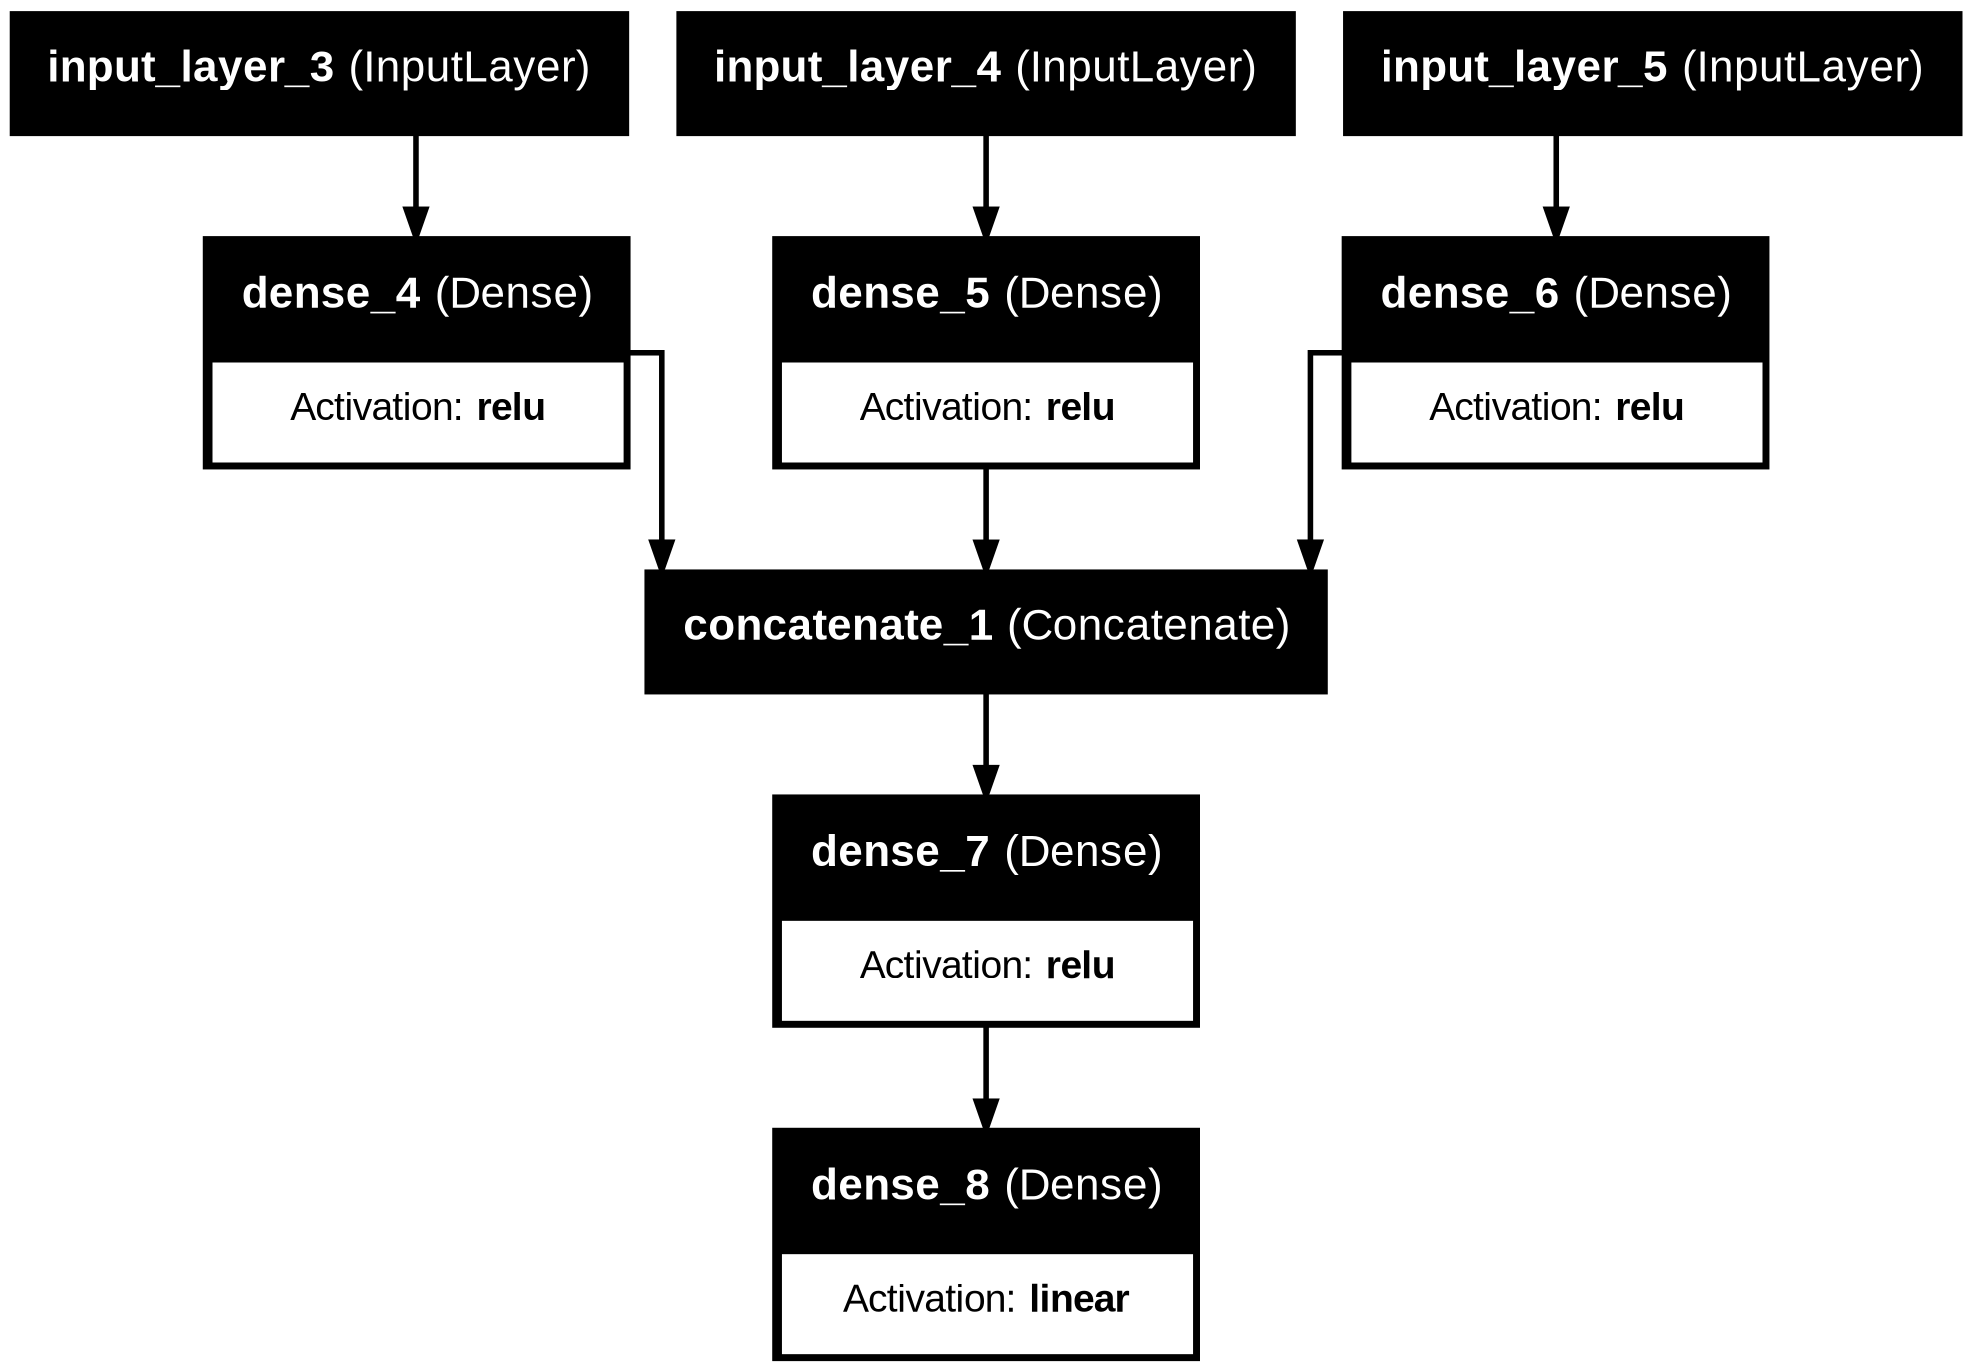

In [25]:
from keras.utils import plot_model

plot_model(model,show_layer_names=True,show_layer_activations=True)